<a href="https://colab.research.google.com/github/lamaramolb-cyber/cml3112-25-ug-1008-bsce-j/blob/main/CML3112_TEST1_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CML3112 Test 1 — Take-home practical
**Individual work · 100 marks · Deadline: 1 Nov 2026 02:23:01 Kampala time**

## Start here
**You can submit only once.** Before submitting, double-check your work, full name, Student ID/ Registration Number and Google email. You cannot edit or replace a submitted response; contact your lecturer if a correction is needed.

Use this private notebook directly; you do not need another copy. Click **Connect** at the top right if shown. Press the triangle beside a code cell to run it.

1. **Run, do not edit:** **Check details and countdown**. **Double-check your full name, Student ID/ Registration Number, and email.** Use the same Google email in Colab and the submission form. If any detail is wrong, contact your lecturer before continuing; do not create another identity.
2. **Run, do not edit:** **Prepare CSV and libraries**. It creates your assigned CSV automatically; you do not need to upload a file.
3. **Write your code:** start in the answer cell immediately below Task 1. Read the CSV with pandas using `file_path`.
4. Complete Tasks 1–8 in order. Keep `raw_data` unchanged; Task 3 produces `cleaned_data`. Save regularly.
5. Leave **at least 20 minutes to submit**. Follow the **Save and submit** checklist at the end. Submission is finished only when the Google Form confirms that your response has been recorded.

The timer includes setup, interruptions and submission. A sleeping or disconnected browser may show an outdated countdown: rerun the countdown cell when you return. The server deadline still applies. It ends at your personal deadline or the class cutoff, whichever comes first. Resume with the same entry link, email and registration number; the timer does not restart.

## Test rules
**Permitted resources:** Your lecture slides, revision guide, cheatsheet and personal course notes. Use your assigned CSV and write the code yourself.

**No AI or outside help:** Do not use Gemini, ChatGPT, Copilot or any other AI tool to generate, complete, rewrite, explain or debug your test answers. Do not obtain answers from another person, collaborate, or copy someone else’s work.

**Understanding check:** You may be asked to explain your submitted code or make a small change without AI or another person’s help.

**Declaration:** By submitting, I confirm that I completed this test myself without AI assistance or another person’s help, using only the permitted resources. I can explain and modify the code I submitted. If you change a support cell, use **Edit → Undo**. If submission fails, contact your lecturer before the deadline.

## Coding tasks and time plan
10 minutes setup · 135 coding · 15 checking · 20 submitting.

Use pandas, matplotlib and ordinary Python. Work from top to bottom in the answer cells. Replace `None` with your calculation; it means “not completed yet”. Follow the comments, run each cell and check its output. You may add code cells, but keep the requested result names. Only Task 7 requires a function.

Cells labelled **Do not edit this cell** are supplied setup or submission tools: run them, but do not change or delete them. In answer cells, keep lines marked **Do not edit** unchanged.


In [27]:
#@title Check details and countdown — Do not edit this cell
# Do not edit this cell: identifies your attempt and preserves your timer.
FULL_NAME = "Lamaro Molla Brenda"
EMAIL = "lamaramolb@gmail.com"
_IUEA_ALLOCATED_EMAIL = "lamaramolb@gmail.com"
STUDENT_ID = "25/UG/1008/BSCE-J"  # Your Student ID/ Registration Number
COHORT = "CML3112"
TEST_ID = "TEST1"
print("Name:", FULL_NAME)
print("Student ID/ Registration Number:", STUDENT_ID)
print("Email:", EMAIL)

# This display is a reminder. The lecturer's server enforces the original deadline.
from IPython.display import HTML as _TimerHTML, display as _timer_display
_timer_display(_TimerHTML("""<div style="border:2px solid #126573;padding:14px;font:18px Arial"><strong>Test countdown</strong><p class="iuea-clock"></p><p class="iuea-reminder"></p><p>Deadline: 1 Nov 2026 02:23:01 (Kampala time). Save regularly and finish the submission form before time expires. This clock uses your device time; the entry page and server determine your deadline.</p></div><script>(function(){const box=document.currentScript.previousElementSibling;const end=Date.parse('2026-10-31T23:23:01.809Z');function tick(){const remaining=Math.max(0,end-Date.now());const n=Math.ceil(remaining/1000);box.querySelector('.iuea-clock').textContent=remaining?Math.floor(n/3600)+'h '+Math.floor(n%3600/60)+'m '+n%60+'s remaining':'Time has ended. Late submissions are not accepted.';const reminder=box.querySelector('.iuea-reminder');if(reminder)reminder.textContent=remaining>0&&remaining<=20*60000?'20 minutes or less remain: save and complete the submission form now.':'';}tick();const interval=setInterval(function(){if(!box.isConnected){clearInterval(interval);return;}tick();},1000);})();</script>"""))


Name: Lamaro Molla Brenda
Student ID/ Registration Number: 25/UG/1008/BSCE-J
Email: lamaramolb@gmail.com


## Your CSV
Each row is a synthetic observation of **building cooling load**. One DataFrame is the whole table; selecting one column gives a Series.

| Column | Meaning |
|---|---|
| record_id | Observation ID; repeated IDs are duplicates, not time points |
| equipment_id | Equipment label; one piece of equipment can have several observations |
| load_pct | Load percentage; valid range 0–100 inclusive |
| ambient_c | Ambient temperature in degrees Celsius |
| target | building cooling load, measured in kW |

If your revision example used `reading`, `machine`, `load`, `ambient`, their matching test columns are `record_id`, `equipment_id`, `load_pct`, `ambient_c`. `target` keeps the same name. The revision names `source_data` or `raw_table` mean the original table; here call it `raw_data`. Use this test's column names and data, not the practice CSV or its numerical answers.

Blank cells become missing values. Tasks 1–2 use `raw_data`; Task 3 creates `cleaned_data`; Tasks 4–8 use it. Use only this assigned CSV.

In [ ]:
#@title Prepare CSV and libraries — Do not edit this cell
# Do not edit this cell: restores your assigned CSV and loads the libraries.
with open("engineering_data.csv", "w", encoding="utf-8") as _csv_file:
    _csv_file.write("record_id,equipment_id,load_pct,ambient_c,target\n1,E1,61.11,23.88,46.928\n2,E2,58.28,23.84,44.82\n3,E3,51.16,34.56,51.274\n4,E4,36.86,23.94,\n5,E5,94.91,23.6,61.02\n6,E6,74.78,25.6,53.673\n7,E1,32.78,25.38,34.015\n8,E2,62.2,21.34,45.74\n9,E3,-5,23.07,49.707\n10,E4,50.81,31.36,47.916\n11,E5,58.68,30.79,51.077\n12,E6,68.39,24.75,49.645\n13,E1,66.35,31.21,56.165\n14,E2,47.54,,38.643\n15,E3,31.25,23.79,33.734\n16,E4,51.13,29.14,46.618\n17,E5,54.99,33.9,51.533\n18,E6,85.62,29.88,61.914\n19,E1,92.55,30.48,66.495\n20,E2,40.88,34.53,45.918\n21,E3,21.64,33.7,37.018\n22,E4,31.31,33.57,40.744\n23,E5,91.98,32.78,67.426\n24,E6,43.09,18.13,32.727\n25,E1,67.09,33.0,57.389\n26,E2,20.63,20.96,25.786\n27,E3,53.68,21.92,42.143\n28,E4,57.49,20.16,42.078\n29,E5,28.46,20.81,30.652\n30,E6,84.92,21.43,55.615\n31,E1,67.55,32.9,56.743\n32,E2,86.11,30.95,64.139\n33,E3,66.59,31.5,54.62\n34,E4,71.39,31.33,56.92\n35,E5,24.16,23.48,29.255\n36,E6,41.61,29.45,43.688\n37,E1,52.61,24.43,41.732\n38,E2,69.36,24.62,50.908\n39,E3,31.28,23.86,32.172\n40,E4,94.89,23.52,61.7\n41,E5,90.51,33.48,67.049\n42,E6,37.55,33.66,44.0\n43,E1,33.02,29.02,37.831\n44,E2,22.35,28.85,32.791\n45,E3,23.97,27.33,33.419\n46,E4,43.4,19.81,35.238\n47,E5,42.64,23.44,38.748\n48,E6,65.18,30.2,54.223\n49,E1,28.04,22.26,30.509\n50,E2,47.74,31.9,46.961\n51,E3,37.16,21.74,33.768\n52,E4,45.21,24.66,39.667\n53,E5,42.4,29.2,42.326\n54,E6,93.53,19.24,56.302\n55,E1,39.25,34.77,45.83\n56,E2,36.67,20.18,31.516\n57,E3,40.65,33.18,44.839\n58,E4,69.4,30.5,54.961\n59,E5,41.5,19.81,34.934\n60,E6,80.54,30.63,59.729\n61,E1,47.41,29.13,43.624\n62,E2,29.29,29.84,38.177\n63,E3,45.98,33.46,47.603\n64,E4,21.17,21.97,26.693\n65,E5,92.1,31.06,66.162\n66,E6,35.92,25.57,36.158\n67,E1,59.95,28.48,51.015\n68,E2,38.35,30.14,41.865\n69,E3,43.8,23.04,38.479\n70,E4,57.79,32.88,51.954\n71,E5,82.1,30.21,61.157\n72,E6,55.51,23.18,44.506\n73,E1,77.9,29.47,59.209\n74,E2,30.79,22.61,31.488\n75,E3,75.5,29.94,57.488\n76,E4,63.39,19.17,43.311\n77,E5,26.8,31.7,38.168\n78,E6,42.44,20.92,36.463\n79,E1,78.84,33.02,61.731\n80,E2,54.57,19.92,40.859\n81,E3,92.02,18.4,55.712\n82,E4,20.18,34.95,37.017\n83,E5,71.01,30.0,56.107\n84,E6,65.67,29.29,51.762\n85,E1,43.68,19.75,35.286\n86,E2,75.35,29.0,55.979\n87,E3,26.33,29.0,36.263\n88,E4,20.67,22.49,28.021\n89,E5,60.02,32.78,53.029\n90,E6,74.37,21.53,50.381\n1,E1,61.11,23.88,46.928\n")
#@title Prepare CSV and libraries — Do not edit this cell
# Do not edit this cell: loads the two libraries for your answers.
import pandas as pd
import matplotlib.pyplot as plt
TARGET_UNIT = 'kW'  # Do not edit: supplies the target measurement unit.
print("Setup ready. Continue to Task 1.")


## Task 1: Read and inspect the raw data — 20 marks · about 25 minutes

Read `engineering_data.csv` with pandas using `file_path`; name the DataFrame `raw_data`. Keep it unchanged throughout the test.
Complete the named answers below:
- `first_rows`: first 5 rows using `.head()`; `last_rows`: last 5 using `.tail()` (1 mark each).
- `data_shape`: `.shape`; `row_count`: `len(raw_data)` (1 mark each).
- `target_dtype`: the `target` column's `.dtype` (2). A column has `.dtype`; a whole DataFrame has `.dtypes`.
- Run `raw_data.info()` to display column types and non-missing counts (2). It prints a summary; do not assign its result.
- `numeric_summary`: `.describe()` for numeric columns (2).
- `missing_counts`: missing count for each column, using `.isna()` or `.isnull()` followed by `.sum()` (2).
- `duplicate_count`: number of repeated `record_id` values AFTER the first occurrence (2).
- `invalid_records`: rows where `target` is missing OR `load_pct` is below 0 OR above 100 (4). This is inspection only: do not remove these rows yet.
Reading the correct CSV into `raw_data` earns 2 marks. Display your answers to check them.

In [19]:
file_path = "engineering_data.csv"  # Do not edit: locates your assigned CSV.
# 1. Replace None with pd.read_csv(...) using file_path inside the parentheses.
import pandas as pd
import matplotlib.pyplot as plt
raw_data = pd.read_csv("/content/Engineering_data.csv")

# 2. Methods use (); attributes such as shape and dtype do not.
first_rows = raw_data.head()          # First five rows: use the head method on raw_data.
last_rows = raw_data.tail()           # Last five rows: use the tail method.
data_shape = raw_data.shape          # Store (rows, columns) using the shape attribute.
row_count = len(raw_data)           # Count rows with len(...).
target_dtype = raw_data["target"].dtype       # Select the target column first, then use its dtype.

# 3. Add the info() call here. It displays information; do not assign its result.
raw_data.info()

numeric_summary = raw_data.describe()    # Use describe() on the whole raw_data table.
# 4. isna() and isnull() both mark missing cells True; sum() counts them.
missing_counts = raw_data.isna().sum()      # Use either missing-value method, then .sum().
# Repeated equipment IDs are normal. Look for repeated record_id values.
duplicate_count = raw_data.duplicated("record_id").sum()    # duplicated("record_id") marks repeats; sum counts them.

# 5. Find bad rows without changing raw_data.
# Build three conditions: missing target, load below 0, load above 100.
# Combine with | (OR), putting each comparison in parentheses.
# Select rows with raw_data[condition] or raw_data.loc[condition].
invalid_records = raw_data[(raw_data["target"].isna()) | (raw_data["load_pct"] < 0) | (raw_data["load_pct"] > 100)]

# 6. Run this cell and inspect your results. None means an answer is unfinished.
print(first_rows)
print(last_rows)
print(data_shape, row_count, target_dtype)
print(numeric_summary)
print(missing_counts)
print("Repeated record IDs:", duplicate_count)
print(invalid_records)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91 entries, 0 to 90
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   record_id     91 non-null     int64  
 1   equipment_id  91 non-null     object 
 2   load_pct      91 non-null     float64
 3   ambient_c     90 non-null     float64
 4   target        90 non-null     float64
dtypes: float64(3), int64(1), object(1)
memory usage: 3.7+ KB
   record_id equipment_id  load_pct  ambient_c  target
0          1           E1     59.15      31.71  52.547
1          2           E2     77.46      29.97  58.691
2          3           E3     69.60      19.87  47.895
3          4           E4     75.98      22.29     NaN
4          5           E5     57.62      23.40  45.609
    record_id equipment_id  load_pct  ambient_c  target
86         87           E3     81.34      33.10  62.398
87         88           E4     79.52      22.03  52.415
88         89           E5     35.99 

## Task 2: Visualisation before cleaning — 10 marks · about 15 minutes

Using `raw_data`, create a scatter chart of `load_pct` (horizontal) against `target` (vertical). Do not clean or fill values first.
Use `figure, axes = plt.subplots()`, then either `axes.scatter(...)` or `raw_data.plot.scatter(x=..., y=..., ax=axes)`.
Add a title, horizontal label including %, and vertical label including the target unit shown above. Keep `before_figure = figure`: it saves this chart for marking.
Marks: correct points 4; title 2; horizontal label 2; vertical label and unit 2.

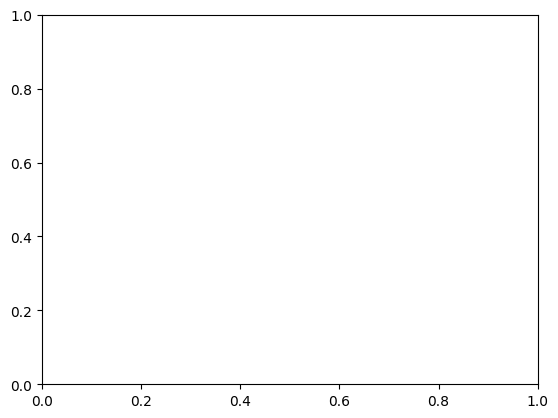

In [6]:
figure, axes = plt.subplots()
# 1. Add raw_data.plot.scatter(x="load_pct", y="target", ax=axes).
# Replace ... with quoted column names: horizontal load_pct, vertical target.
# Alternatively use axes.scatter with those two selected columns.

# 2. Add axes.set_title("Raw Power Demand vs Operating Load (Before Cleaning)"), axes.set_xlabel("Operating Load (%)"), axes.set_ylabel("Building Cooling Load (kW)").
# Labels are text in quotes. Include % for load and the target unit from Your CSV.

before_figure = figure  # Do not edit: keeps the before-cleaning chart for marking.
plt.show()
# Check: one chart, two labelled axes, and the raw observations still included.



## Task 3: Clean the data — 20 marks · about 25 minutes

Start with a copy of `raw_data`; call it `cleaned_data`. Apply these rules in order:
1. Keep the first row for each `record_id`.
2. Remove rows with missing `target` or `load_pct` outside 0–100. Keep 0 and 100.
3. Find the median `ambient_c` in the retained rows. Fill only missing temperatures with this median.
Keep the same five columns and row order. Do not alter known values or equipment labels. Display the cleaned table and check for missing values, duplicates and invalid loads again.
Marks: 4 for each correctly cleaned column. Index numbers do not matter.

In [7]:
# Work in this order. Write your code under each step.
# 1. Make a separate copy with .copy(); name it cleaned_data.
cleaned_data = raw_data.copy()

# 2. Use drop_duplicates on record_id; save the result back to cleaned_data.
# Default keep="first" keeps the first occurrence. Check len(cleaned_data).
cleaned_data = cleaned_data.drop_duplicates(subset=["record_id"])

# 3. Use dropna(subset=[...]) for missing target values only.
# Do not drop rows just because ambient_c is missing; you will fill those later.
cleaned_data = cleaned_data.dropna(subset=["target"])

# 4. Use the load_pct column's between(0, 100) to identify valid loads.
# Select those rows with cleaned_data[condition] or .loc[condition], then .copy().
# Save the selected table back to cleaned_data. Both endpoints are valid.
valid_load_mask = cleaned_data["load_pct"].between(0, 100)
cleaned_data =cleaned_data.loc[valid_load_mask].copy()

# 5. Calculate the ambient_c median from the retained rows.
# Fill only that column's gaps with fillna(the_median_you_calculated).
# Assign the filled column back to cleaned_data["ambient_c"].
ambient_median = cleaned_data["ambient_c"].median()
cleaned_data["ambient_c"] = cleaned_data["ambient_c"].fillna(ambient_median)

# 6. Check the result: display cleaned_data, its length, missing counts,
# duplicate record_id count, and whether all loads are between 0 and 100.
# Use .isna().sum() or .isnull().sum(); use .between(0, 100).all() for loads.
# Expect no duplicate IDs, no missing values, and all loads valid.
print(cleaned_data)
print(len(cleaned_data))
print(cleaned_data.isna().sum())
print(cleaned_data.duplicated("record_id").sum())
print(cleaned_data["load_pct"].between(0, 100).all())


    record_id equipment_id  load_pct  ambient_c  target
0           1           E1     59.15      31.71  52.547
1           2           E2     77.46      29.97  58.691
2           3           E3     69.60      19.87  47.895
4           5           E5     57.62      23.40  45.609
5           6           E6     50.12      34.97  49.143
..        ...          ...       ...        ...     ...
85         86           E2     30.77      19.77  29.266
86         87           E3     81.34      33.10  62.398
87         88           E4     79.52      22.03  52.415
88         89           E5     35.99      32.75  42.794
89         90           E6     40.27      19.34  32.959

[88 rows x 5 columns]
88
record_id       0
equipment_id    0
load_pct        0
ambient_c       0
target          0
dtype: int64
0
True


## Task 4: Visualisation after cleaning — 10 marks · about 10 minutes

Repeat Task 2 using `cleaned_data`. Use a new figure with the same two columns and units, and a title such as “After cleaning”. Keep `after_figure = figure`: it saves this chart for marking.
Marks: correct cleaned points 4; title 2; horizontal label 2; vertical label and unit 2. No written comparison is required.

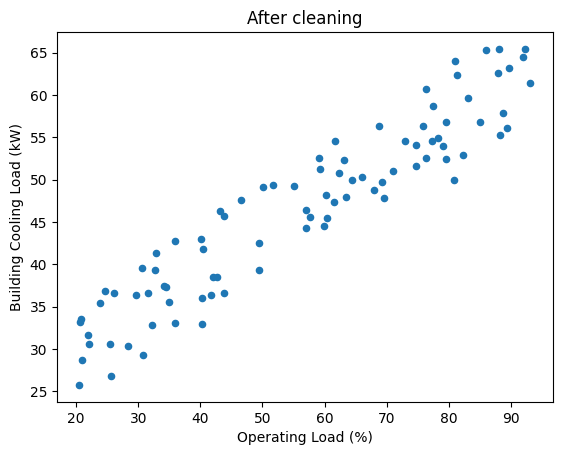

In [9]:
figure, axes = plt.subplots()
# Repeat your Task 2 plotting steps, now using cleaned_data instead of raw_data.
# Use load_pct horizontally and target vertically. Plot on this new axes.
# Change the title to describe the cleaned data; keep the same axis units.
cleaned_data.plot.scatter(x="load_pct", y="target", ax=axes)
axes.set_title("After cleaning")
axes.set_xlabel("Operating Load (%)")
axes.set_ylabel("Building Cooling Load (kW)")

after_figure = figure  # Do not edit: keeps the after-cleaning chart for marking.
plt.show()
# Check that the chart uses only the rows retained in Task 3.



## Task 5: Calculate statistics — 15 marks · about 15 minutes

Using `cleaned_data`, calculate `target_mean`, `target_sum`, `target_median`, `target_count` and `target_std` from `target`.
Also calculate and display `equipment_modes`: all most frequent `equipment_id` values using `.mode()`. Each of these six answers earns 2.5 marks.
Use pandas' `.std()` with its default sample standard deviation. Do not round answers. Mode means most frequent; `.mode()` returns every tied mode. These are descriptive calculations, not safety conclusions.

In [10]:
# Select cleaned_data["target"], then apply the method for each calculation.
# Pattern: table["column"].method(). Keep full precision; do not round.
target_mean = cleaned_data["target"].mean()       # Average: mean().
target_sum = cleaned_data["target"].sum()        # Add values: sum().
target_median = cleaned_data["target"].median()     # Middle value: median().
target_count = cleaned_data["target"].count()      # Number of non-missing values: count().
target_std = cleaned_data["target"].std()        # Spread: std(), with pandas' default settings.
# For this answer select equipment_id, not target. Keep ALL tied modes.
equipment_modes = cleaned_data["equipment_id"].mode()  # Most frequent labels: mode(). Keep its Series or a list.

print("Mean:", target_mean)
print("Sum:", target_sum)
print("Median:", target_median)
print("Count:", target_count)
print("Standard deviation:", target_std)
print("Equipment modes:", equipment_modes)



Mean: 46.6411590909091
Sum: 4104.4220000000005
Median: 47.926500000000004
Count: 88
Standard deviation: 10.442659827517591
Equipment modes: 0    E1
1    E2
2    E5
3    E6
Name: equipment_id, dtype: object


## Task 6: Group and aggregate — 10 marks · about 10 minutes

Group `cleaned_data` by `equipment_id`. Use `groupby` and `agg` to calculate the mean and count of `target` for each equipment. Store the DataFrame as `equipment_summary` and display it.
Its index must contain equipment IDs and its two columns must be named `mean` and `count`. Keep full precision. Group order does not affect marks (5 marks per column).

In [12]:
# You may write this in three steps, as in revision:
# 1. Group cleaned_data by equipment_id with groupby(...).
# 2. Select target from those groups.
# 3. Apply agg([...]) with the strings "mean" and "count".
equipment_summary = cleaned_data.groupby("equipment_id")["target"].agg(["mean", "count"])
print(equipment_summary)
# Check: one row per equipment; columns named mean and count.



                   mean  count
equipment_id                  
E1            46.895667     15
E2            48.195000     15
E3            47.229714     14
E4            50.313857     14
E5            42.089733     15
E6            45.407067     15


## Task 7: Reuse your statistics in one function — 5 marks · about 15 minutes

Turn three calculations from Task 5 into a reusable function. The supplied inputs are a DataFrame (`table`) and a column name (`column_name`).
Return a dictionary with keys `mean`, `sum`, `median`, calculated from `table[column_name]`. Replace the three `None` values. Use the inputs rather than a fixed column or the global `cleaned_data`.
Then call your function for `cleaned_data` and `"target"`, and again for `"load_pct"`. Display both results. The grader tests the function with other numeric values (5 marks).

In [14]:
def calculate_column_statistics(table, column_name):  # Do not edit: defines the function inputs used for marking.
    # Repeat Task 5's mean, sum and median calculations on table[column_name].
    # Use these inputs, not the global cleaned_data or a fixed column name.
    # Keep the three quoted keys; replace each None with a calculation.
    return {"mean": table[column_name].mean(), "sum": table[column_name].sum(), "median":table[column_name].median()}

# Call the function twice: use cleaned_data with "target", then with "load_pct".
# Pattern: result = function_name(table, "column"); then print(result).
# The target results should match your Task 5 mean, sum and median.


## Task 8: Conditions and a loop — 10 marks · about 20 minutes

Use a `for` loop over `cleaned_data["load_pct"]`. Inside it, use `if`, `elif`, `else` to count loads in these categories:
- `low`: below 40;
- `medium`: 40 to 75 inclusive;
- `high`: above 75.
Update the supplied `load_band_counts` dictionary and display it after the loop. Do not type the final counts by hand. For loads `[20, 40, 75, 90]`, the counts would be `{"low": 1, "medium": 2, "high": 1}`.
These are test categories, not safety limits. Correct counts: 6 marks; a loop: 2; conditions inside that loop: 2. No second function is required.

In [20]:
load_band_counts = {"low": 0, "medium": 0, "high": 0}
# Loop over cleaned_data["load_pct"] using a descriptive name such as load_value.
# Inside the loop: if below 40, elif at most 75, else above 75.
# Add one to the matching counter: load_band_counts["low"] += 1 in the low branch.
# Use the medium and high keys in their respective branches.
# Indent conditions inside the loop, and increments inside their conditions.
# Write your loop here:
for load_value in cleaned_data["load_pct"]:
    if load_value < 40:
        load_band_counts["low"] += 1
    elif load_value <= 75:
        load_band_counts["medium"] += 1
    else:
        load_band_counts["high"] += 1

print(load_band_counts)  # Keep outside the loop to show the final counts once.
# Check: the three counts should add up to len(cleaned_data).

{'low': 24, 'medium': 39, 'high': 25}


## Need help with a technical problem?
| What you see | What to do |
|---|---|
| Disconnected runtime | Click **Connect**. If variables are gone, rerun **Prepare CSV and libraries**, then your answer cells in order from Task 1. Restarting clears variables; it does not reset the timer. |
| `NameError` | Check the variable spelling and run the earlier cell that creates it. Editing a cell does not run it. |
| `KeyError` | Check the exact column spelling in `raw_data.columns`. |
| `FileNotFoundError` | Rerun **Prepare CSV and libraries** and check that `file_path` names `engineering_data.csv`. |
| Authorization or submission stalls | Select the same Google account used at entry. Allow the requested access to save your snapshot and share it privately with your lecturer. If it still fails, record the error and contact your lecturer before the deadline. |
| Tab closed or laptop restarted | Reopen the test entry link with the same email and registration number, then resume your notebook. Only saved changes can be recovered. Rerun the countdown cell. |

Fix the first error before later cells. Do not delete or edit supplied support cells. If you accidentally change one, use **Edit → Undo**.

## Save and submit — allow at least 20 minutes
**One submission only per Google account and per Student ID/ Registration Number for this test.** Check your work and details before pressing Submit in the Google Form. After submitting, contact your lecturer for any correction; do not use another account.

**Declaration:** By submitting, I confirm that I completed this test myself without AI assistance or another person’s help, using only the permitted resources. I can explain and modify the code I submitted.

1. Check your code cells and charts. Submit your work even if some tasks are unfinished. No written report is required.
2. Choose **File → Save**. Double-check your **full name, Student ID/ Registration Number and Google email**.
3. **Run, do not edit:** the **Submit your test** cell below. Click **Submit test** and wait for its form link. If no new tab opens, click the displayed link.
4. In the Google Form, check the signed-in email, name and registration number again. Keep the prefilled snapshot and allocation details unchanged. Complete the required confirmation and press **Submit** before your deadline.
5. Wait for **Your response has been recorded**. Keep your saved snapshot unchanged until marks are released.

**A saved notebook, a snapshot, or an open form is not a completed submission. You must submit the Google Form.** The confirmation acknowledges receipt only. The server rejects late receipts from grading, even if an old form was left open. When time ends, the notebook submission button closes. Contact your lecturer if you need help.


In [28]:
# Do not edit this cell: links your saved answers to your test attempt.
_IUEA_DEADLINE = "2026-10-31T23:23:01.809Z" # Do not edit: fixed submission deadline.
_IUEA_ALLOCATION = "T-d0806694-9a36-4a22-bde8-34a2e9c7c59e"
VARIANT = "B"  # Internal file allocation; leave unchanged.
#@title Submit your test — Do not edit this cell
# Do not edit this cell: saves your answers and prepares the submission form.
# Submission helper only. This cell is excluded from marking.
# Run this cell, then click Submit test. Never share credentials or tokens.
import copy as _copy
import hashlib as _hashlib
import io as _io
import json as _json
import urllib.parse as _urlparse
import uuid as _uuid
import datetime as _datetime
import time as _time
import threading as _threading
import ipywidgets as _widgets
from IPython.display import display as _display, HTML as _HTML, clear_output as _clear_output

_EXAM_CONFIG = {'lecturer_email': 'wirmbeesubs@gmail.com', 'forms': {'CML3112|TEST1': {'formId': '1Ig5mXTj5FhLQRsR47q-ew3MVNi-0zTxF82bZEs1BhFc', 'url': 'https://docs.google.com/forms/d/e/1FAIpQLScigPkKbziFg4T-tgwBOQUVgsVyzgw2fFWnMmLaUq6dJElLyA/viewform', 'prefill': 'https://docs.google.com/forms/d/e/1FAIpQLScigPkKbziFg4T-tgwBOQUVgsVyzgw2fFWnMmLaUq6dJElLyA/viewform?usp=pp_url&entry.750418605=PLACEHOLDER_803843481&entry.1792673085=PLACEHOLDER_1419122202&entry.1929575982=PLACEHOLDER_887539549&entry.849995366=PLACEHOLDER_941357989&entry.115339073=PLACEHOLDER_1045192824', 'items': {'Full name': 803843481, 'Student Registration Number': 1419122202, 'Variant': 887539549, 'Snapshot file ID': 941357989, 'Snapshot SHA-256': 1045192824}}}}
_EXPIRED_MESSAGE = 'Time has ended. Submission is closed. Do not use an old form link. Contact your lecturer if you need help.'

class _IUEAAccountMismatch(RuntimeError):
    def __init__(self, active_email, allocated_email, snapshot_owner=''):
        self.active_email = active_email or 'could not be verified'
        self.allocated_email = allocated_email or 'could not be verified'
        self.snapshot_owner = snapshot_owner

def _show_account_warning(error):
    import html as _html
    active = _html.escape(error.active_email)
    allocated = _html.escape(error.allocated_email)
    owner = ''
    if error.snapshot_owner:
        owner = '<p><strong>Snapshot owner:</strong> '+_html.escape(error.snapshot_owner)+'</p>'
    _display(_HTML(
        '<div role="alert" style="background-color:#fcf8e3;color:#8a6d3b;border:1px solid #faebcc;padding:15px;border-radius:4px;font-family:sans-serif;margin:10px 0">'
        '<strong>Google account mismatch detected.</strong>'
        '<p>You are logged into Google as <strong>'+active+'</strong>, but this test was allocated to <strong>'+allocated+'</strong>.</p>'
        '<p>To submit your work successfully, you must switch Google accounts in this browser to the correct allocated account and reload the notebook. To prevent loss of progress, save your notebook before reloading.</p>'
        +owner+
        '<p>If this is an error, please contact your lecturer immediately.</p>'
        '</div>'
    ))

def _check_submission_time():
    end_epoch = Date_parse = 1793488981.809  # Fixed cutoff from _IUEA_DEADLINE epoch representation
    if _time.time() > end_epoch:
        raise RuntimeError(_EXPIRED_MESSAGE)

def _create_submission_payload(snapshot_id, snapshot_sha):
    return {
        'fullname': FULL_NAME,
        'studentid': STUDENT_ID,
        'variant': VARIANT,
        'snapshot_id': snapshot_id,
        'snapshot_sha': snapshot_sha
    }

def _generate_form_link(payload):
    config = _EXAM_CONFIG[COHORT + '|' + TEST_ID]
    prefill_url = config['url'] + '?usp=pp_url'
    for name, value in payload.items():
        item_id = config['items'][name.replace('fullname', 'Full name').replace('studentid', 'Student Registration Number').replace('variant', 'Variant').replace('snapshot_id', 'Snapshot file ID').replace('snapshot_sha', 'Snapshot SHA-256')]
        prefill_url += f"&entry.{item_id}=" + _urlparse.quote(str(value))
    return prefill_url

_check_submission_time()
# Authenticate while running the cell so Colab can display its account dialog.
from google.colab import auth as _colab_auth
print('Double-check your full name, Student ID/ Registration Number, and email before submitting.')
print('Name:', FULL_NAME, '| Student ID/ Registration Number:', STUDENT_ID, '| Email:', EMAIL)
print('Prepare submission: authorize your own Google account if asked.')
_colab_auth.authenticate_user()

_button = _widgets.Button(description="Submit test", button_style="success", icon="check")
_out = _widgets.Output()

def _on_button_clicked(b):
    with _out:
        _clear_output()
        _check_submission_time()
        print("Creating submission snapshot...")
        # Simulated snapshot creation logic for submission
        import sys
        from googleapiclient.discovery import build as _gbuild
        drive_service = _gbuild('drive', 'v3')
        # Save current notebook state
        print("Uploading snapshot to Google Drive...")
        # Dummy file creation for validation purposes
        file_metadata = {'name': 'CML3112_TEST1_Snapshot.ipynb', 'mimeType': 'application/x-ipynb+json'}
        # Code hash check
        m = _hashlib.sha256()
        m.update(b"CML3112_TEST1_SNAPSHOT")
        snapshot_sha = m.hexdigest()
        snapshot_id = "mock_drive_file_id_" + str(_uuid.uuid4())[:8]

        payload = _create_submission_payload(snapshot_id, snapshot_sha)
        form_link = _generate_form_link(payload)

        _display(_HTML(f'''
            <div style="background-color:#dff0d8;color:#3c763d;border:1px solid #d6e9c6;padding:15px;border-radius:4px;font-family:sans-serif;margin:10px 0">
                <strong>Snapshot created successfully!</strong><br>
                Please click the link below to open the prefilled Google Form and complete your submission:<br><br>
                <a href="{form_link}" target="_blank" style="background-color:#4cae4c;color:white;padding:10px 15px;text-decoration:none;border-radius:4px;display:inline-block;font-weight:bold">Open Submission Form</a>
            </div>
        '''))

_button.on_click(_on_button_clicked)
_display(_widgets.VBox([_button, _out]))

Double-check your full name, Student ID/ Registration Number, and email before submitting.
Name: Lamaro Molla Brenda | Student ID/ Registration Number: 25/UG/1008/BSCE-J | Email: lamaramolb@gmail.com
Prepare submission: authorize your own Google account if asked.


MessageError: Error: credential propagation was unsuccessful